# EDA de la ENIGH 2024: principales variables por hogar

Antes de construir queremos saber qué tipo de variables tenemos, cómo se distribuyen, si hay huecos o valores raros, y cuáles dicen prácticamente lo mismo.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy import stats
from sklearn.metrics import normalized_mutual_info_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)

import warnings
warnings.simplefilter("ignore", pd.errors.PerformanceWarning)  # avisos de pandas al agregar columnas

RAW = Path("../data/raw")

### Cargar los datos

Los folios y algunas claves (entidad-municipio, estrato de diseño, UPM y educación del jefe) traen ceros a la izquierda, asi que van como texto. Si no, `01001` se convierte en `1001` y ya no podemos sacar la entidad.

In [2]:
claves = ["folioviv", "foliohog", "ubica_geo", "est_dis", "upm", "educa_jefe"]
df = pd.read_csv(RAW / "concentradohogar.csv", dtype={c: str for c in claves})
df.shape

(91414, 126)

In [3]:
df.head()

,folioviv,foliohog,ubica_geo,tam_loc,est_socio,est_dis,upm,factor,clase_hog,sexo_jefe,edad_jefe,educa_jefe,tot_integ,hombres,mujeres,mayores,menores,p12_64,p65mas,ocupados,percep_ing,perc_ocupa,ing_cor,ingtrab,trabajo,...,esparci,paq_turist,personales,cuida_pers,acces_pers,otros_gas,transf_gas,percep_tot,retiro_inv,prestamos,otras_perc,ero_nm_viv,ero_nm_hog,erogac_tot,cuota_viv,mater_serv,material,servicio,deposito,prest_terc,pago_tarje,deudas,balance,otras_erog,smg
0,0100001901,1,01001,1,3,001,0000001,207,2,1,32,06,4,2,2,2,2,2,0,2,2,2,"138,232.38","130,518.10","130,518.10",...,0.00,0.00,116.12,116.12,0.00,0.00,0.00,"13,499.97",0.00,0.00,0.00,0.00,"13,499.97","29,582.60",0.00,0.00,0.00,0.00,"21,365.21",0.00,0.00,"8,217.39",0.00,0.00,"22,403.70"
1,0100001902,1,01001,1,3,001,0000001,207,2,1,48,09,4,2,2,4,0,4,0,2,2,2,"118,014.04","103,829.72","103,829.72",...,839.02,0.00,"3,135.44","3,135.44",0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,"8,709.67","8,709.67",0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,"22,403.70"
2,0100001904,1,01001,1,3,001,0000001,207,2,2,60,06,2,1,1,2,0,2,0,2,2,2,"46,866.32","45,580.61","45,580.61",...,0.00,0.00,"1,381.91","1,381.91",0.00,0.00,0.00,"5,435.96",0.00,0.00,0.00,0.00,"5,435.96","4,695.65",0.00,0.00,0.00,0.00,"4,695.65",0.00,0.00,0.00,0.00,0.00,"22,403.70"
3,0100001905,1,01001,1,3,001,0000001,207,2,1,43,08,4,3,1,4,0,4,0,3,3,3,"110,430.10","97,169.95","97,169.95",...,"4,151.82",0.00,"2,554.79","2,554.79",0.00,0.00,0.00,"6,847.82",0.00,"6,847.82",0.00,0.00,0.00,"22,768.99",0.00,366.84,366.84,0.00,"5,869.56",0.00,"7,336.95","2,934.78",0.00,"6,260.86","22,403.70"
4,0100002501,1,01001,1,2,002,0000002,196,2,2,29,08,4,1,3,2,2,2,0,2,2,2,"99,494.12","93,687.67","93,687.67",...,"5,934.70","1,369.56","22,825.56","21,878.61",898.04,48.91,"10,122.77","35,706.51","35,706.51",0.00,0.00,0.00,0.00,"16,145.46","6,096.77",0.00,0.00,0.00,0.00,"2,934.78",0.00,0.00,0.00,"7,113.91","22,403.70"


In [4]:
df.dtypes.value_counts()

float64    104
int64       16
str          6
Name: count, dtype: int64

In [5]:
# ¿cada fila es un hogar distinto?
df["id_hogar"] = df["folioviv"] + "_" + df["foliohog"]
print("id_hogar único:", df["id_hogar"].is_unique)
print("filas duplicadas:", df.duplicated().sum())
print(f"memoria: {df.memory_usage(deep=True).sum() / 1e6:.0f} MB")

id_hogar único: True
filas duplicadas: 0
memoria: 123 MB


Son 91,414 hogares y 124 columnas (más las que vamos creando). Cada fila es un hogar distinto y no hay filas repetidas. Casi todo es numerico: 104 columnas float (los montos en pesos), 16 enteras y las 6 claves que leímos como texto.

### ¿Qué tipo de variable es cada una?

In [6]:
perfil = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "n_unicos": df.nunique(),
    "pct_ceros": (df == 0).mean().mul(100).round(1),
})
perfil.sort_values("n_unicos").head(25)

,tipo,n_unicos,pct_ceros
smg,float64,1,0.00
sexo_jefe,int64,2,0.00
est_socio,int64,4,0.00
foliohog,str,4,0.00
tam_loc,int64,4,0.00
clase_hog,int64,5,0.00
p65mas,int64,6,73.50
menores,int64,10,61.20
educa_jefe,str,11,0.00
perc_ocupa,int64,12,11.60


Con esto y el catálogo (pág. 215 del PDF en `docs/`) las acomodamos a mano. Números pero no se pueden sumar ni promediar: `tam_loc`, `est_socio` o `educa_jefe` son códigos con orden, y `clase_hog` o `sexo_jefe` son etiquetas sin orden. De `ubica_geo` sacamos la entidad (los dos primeros dígitos), municipio tiene demasiados valores para explorarlo así.

In [7]:
df["entidad"] = df["ubica_geo"].str[:2]

ids = ["folioviv", "foliohog", "id_hogar", "ubica_geo"]
diseno = ["upm", "est_dis", "factor"]  # vienen del diseño de la muestra, no describen al hogar
nominales = ["entidad", "clase_hog", "sexo_jefe"]
ordinales = ["tam_loc", "est_socio", "educa_jefe"]
discretas = ["edad_jefe", "tot_integ", "hombres", "mujeres", "mayores", "menores",
             "p12_64", "p65mas", "ocupados", "percep_ing", "perc_ocupa"]

ya_usadas = set(ids + diseno + nominales + ordinales + discretas)
montos = [c for c in df.columns if c not in ya_usadas]  # todo lo demás son pesos por trimestre

pd.Series({"identificadores": len(ids), "diseño muestral": len(diseno), "nominales": len(nominales),
           "ordinales": len(ordinales), "discretas": len(discretas), "montos": len(montos)})

identificadores      4
diseño muestral      3
nominales            3
ordinales            3
discretas           11
montos             104
dtype: int64

In [8]:
etiquetas = {
    "tam_loc": {1: "100 mil y más", 2: "15 mil a 99,999", 3: "2,500 a 14,999", 4: "Menos de 2,500"},
    "est_socio": {1: "Bajo", 2: "Medio bajo", 3: "Medio alto", 4: "Alto"},
    "clase_hog": {1: "Unipersonal", 2: "Nuclear", 3: "Ampliado", 4: "Compuesto", 5: "Corresidente"},
    "sexo_jefe": {1: "Hombre", 2: "Mujer"},
    "educa_jefe": {"01": "Sin instrucción", "02": "Preescolar", "03": "Primaria incompleta",
                   "04": "Primaria completa", "05": "Secundaria incompleta", "06": "Secundaria completa",
                   "07": "Prepa incompleta", "08": "Prepa completa", "09": "Profesional incompleta",
                   "10": "Profesional completa", "11": "Posgrado"},
    "entidad": {"01": "Aguascalientes", "02": "Baja California", "03": "Baja California Sur",
                "04": "Campeche", "05": "Coahuila", "06": "Colima", "07": "Chiapas", "08": "Chihuahua",
                "09": "Ciudad de México", "10": "Durango", "11": "Guanajuato", "12": "Guerrero",
                "13": "Hidalgo", "14": "Jalisco", "15": "México", "16": "Michoacán", "17": "Morelos",
                "18": "Nayarit", "19": "Nuevo León", "20": "Oaxaca", "21": "Puebla", "22": "Querétaro",
                "23": "Quintana Roo", "24": "San Luis Potosí", "25": "Sinaloa", "26": "Sonora",
                "27": "Tabasco", "28": "Tamaulipas", "29": "Tlaxcala", "30": "Veracruz",
                "31": "Yucatán", "32": "Zacatecas"},
}

# columnas con la etiqueta en texto, solo para tablas y gráficas
for col, mapa in etiquetas.items():
    orden = list(mapa.values())
    df[col + "_et"] = pd.Categorical(df[col].map(mapa), categories=orden, ordered=col in ordinales)

### Huecos, constantes y ceros

In [9]:
print("valores nulos en toda la base:", df.isna().sum().sum())
constantes = [c for c in df.columns if df[c].nunique() == 1]
print("columnas constantes:", constantes, "->", df[constantes].iloc[0].to_dict())

valores nulos en toda la base: 0
columnas constantes: ['smg'] -> {'smg': 22403.7}


Ni un solo nulo. Suena bien pero la verdad en una encuesta de gastos es raro que todos contesten todo, así que lo más probable es que "no gastó" o "no reportó" esté guardado como 0?

`smg` es el salario mínimo general (22,403.70 al trimestre) y es igual para todos los hogares. No aporta nada para distinguir hogares, asi que lo sacamos de los montos

In [10]:
montos.remove("smg")

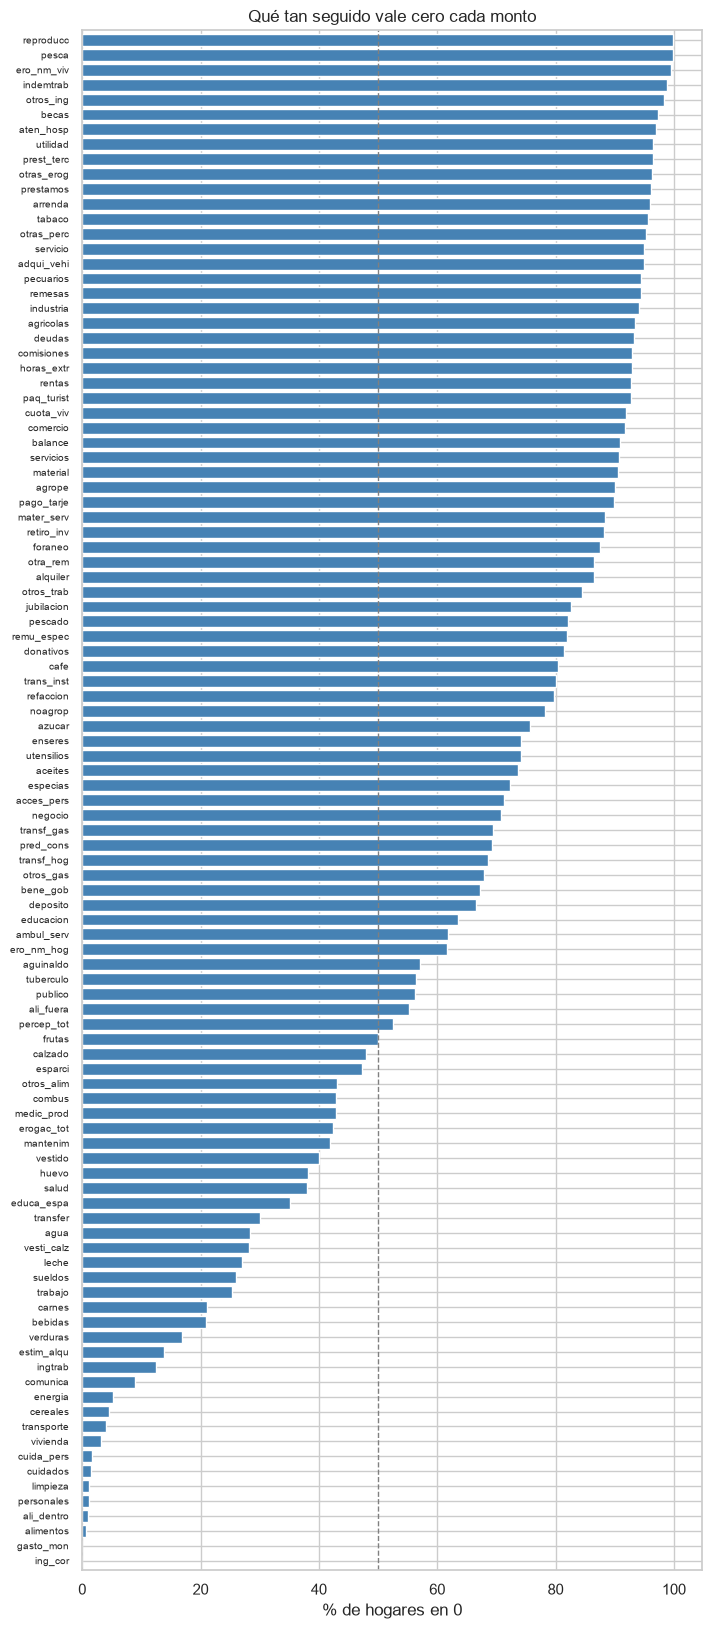

In [11]:
ceros = (df[montos] == 0).mean().mul(100).sort_values()

fig, ax = plt.subplots(figsize=(8, 20))
ceros.plot.barh(ax=ax, color="steelblue", width=0.8)
ax.axvline(50, color="gray", ls="--", lw=1)
ax.set(xlabel="% de hogares en 0", ylabel="", title="Qué tan seguido vale cero cada monto")
ax.tick_params(axis="y", labelsize=7)
plt.show()

In [12]:
print("montos con más de la mitad en cero:", (ceros > 50).sum(), "de", len(ceros))
print("montos con más de 90% en cero:", (ceros > 90).sum())
ceros[ceros > 90].round(1).to_frame("% en cero").T

montos con más de la mitad en cero: 68 de 103
montos con más de 90% en cero: 31


,agrope,material,servicios,balance,comercio,cuota_viv,paq_turist,rentas,horas_extr,comisiones,deudas,agricolas,industria,remesas,pecuarios,adqui_vehi,servicio,otras_perc,tabaco,arrenda,prestamos,otras_erog,prest_terc,utilidad,aten_hosp,becas,otros_ing,indemtrab,ero_nm_viv,pesca,reproducc
% en cero,90.10,90.50,90.70,90.90,91.70,91.90,92.70,92.70,92.90,92.90,93.30,93.50,94.10,94.40,94.50,95.00,95.00,95.20,95.60,95.90,96.10,96.20,96.40,96.50,97.00,97.20,98.20,98.80,99.50,99.80,99.80


68 de los 103 montos valen cero en más de la mitad de los hogares y 31 lo hacen en más del 90%. Me imagino que hay de dos tipos: los que son cero porque casi nadie tiene ese ingreso o gasto (pesca, becas, remesas, hospitalización, comprar coche) y los totales grandes que casi nunca son cero (ingreso corriente, gasto monetario, alimentos).

Para las del primer tipo, el monto en sí dice poco. Lo que más informa es si el hogar tiene o no ese gasto. Si las usamos mas adelante probablemente conviene convertirlas en un sí/no o juntarlas en su total.

### Variables que son suma de otras

Leyendo el catálogo se ve que muchas columnas son totales: el ingreso corriente se arma con trabajo, rentas, transferencias, etc., y el gasto monetario con alimentos, vivienda, salud, etc. Vamos a ver si de verdad cuadrann

In [13]:
jerarquia = {
    "ing_cor": ["ingtrab", "rentas", "transfer", "estim_alqu", "otros_ing"],
    "ingtrab": ["trabajo", "negocio", "otros_trab"],
    "trabajo": ["sueldos", "horas_extr", "comisiones", "aguinaldo", "indemtrab", "otra_rem", "remu_espec"],
    "negocio": ["noagrop", "agrope"],
    "noagrop": ["industria", "comercio", "servicios"],
    "agrope": ["agricolas", "pecuarios", "reproducc", "pesca"],
    "rentas": ["utilidad", "arrenda"],
    "transfer": ["jubilacion", "becas", "donativos", "remesas", "bene_gob", "transf_hog", "trans_inst"],
    "gasto_mon": ["alimentos", "vesti_calz", "vivienda", "limpieza", "salud", "transporte",
                  "educa_espa", "personales", "transf_gas"],
    "alimentos": ["ali_dentro", "ali_fuera", "tabaco"],
    "ali_dentro": ["cereales", "carnes", "pescado", "leche", "huevo", "aceites", "tuberculo", "verduras",
                   "frutas", "azucar", "cafe", "especias", "otros_alim", "bebidas"],
    "vesti_calz": ["vestido", "calzado"],
    "vivienda": ["alquiler", "pred_cons", "agua", "energia"],
    "limpieza": ["cuidados", "utensilios", "enseres"],
    "salud": ["ambul_serv", "aten_hosp", "medic_prod"],
    "transporte": ["publico", "foraneo", "adqui_vehi", "mantenim", "refaccion", "combus", "comunica"],
    "educa_espa": ["educacion", "esparci", "paq_turist"],
    "personales": ["cuida_pers", "acces_pers", "otros_gas"],
    "percep_tot": ["retiro_inv", "prestamos", "otras_perc", "ero_nm_viv", "ero_nm_hog"],
    "erogac_tot": ["cuota_viv", "mater_serv", "deposito", "prest_terc", "pago_tarje", "deudas",
                   "balance", "otras_erog"],
    "mater_serv": ["material", "servicio"],
}

def revisar_suma(total, partes):
    dif = (df[total] - df[partes].sum(axis=1)).abs()
    return pd.Series({"pct_cuadra": (dif < 1).mean() * 100, "dif_max": dif.max()})

pd.DataFrame({t: revisar_suma(t, p) for t, p in jerarquia.items()}).T

,pct_cuadra,dif_max
ing_cor,100.00,0.00
ingtrab,100.00,0.00
trabajo,100.00,0.00
negocio,100.00,0.00
noagrop,100.00,0.00
agrope,100.00,0.00
rentas,100.00,0.00
transfer,100.00,0.00
gasto_mon,100.00,0.00
alimentos,100.00,0.00


Todas cuadran menos `transporte`. Resulta que `refaccion` y `combus` no son hermanas de `mantenim`, son sus hijas:

In [14]:
print(revisar_suma("mantenim", ["refaccion", "combus"]).to_dict())
jerarquia["transporte"] = ["publico", "foraneo", "adqui_vehi", "mantenim", "comunica"]
jerarquia["mantenim"] = ["refaccion", "combus"]
print(revisar_suma("transporte", jerarquia["transporte"]).to_dict())

{'pct_cuadra': 100.0, 'dif_max': 1.4551915228366852e-11}
{'pct_cuadra': 100.0, 'dif_max': 2.3283064365386963e-10}


In [15]:
# lo mismo con las personas del hogar
print("tot_integ = hombres + mujeres:", (df["tot_integ"] == df["hombres"] + df["mujeres"]).mean())
print("tot_integ = mayores + menores:", (df["tot_integ"] == df["mayores"] + df["menores"]).mean())
print("mayores = p12_64 + p65mas:", (df["mayores"] == df["p12_64"] + df["p65mas"]).mean())

tot_integ = hombres + mujeres: 1.0
tot_integ = mayores + menores: 1.0
mayores = p12_64 + p65mas: 1.0


O sea que la base está armada como un árbol: el ingreso corriente se parte en trabajo, rentas, transferencias, etc., y cada uno se vuelve a partir. Lo mismo con el gasto y con las personas del hogar (`tot_integ` = hombres + mujeres = mayores + menores).

Esto importa porque meter un total junto con todas sus partes es meter la misma información dos veces.

### ¿Cómo se ven los montos?

Nos quedamos con los totales grandes para darnos una idea, y medimos dónde está el centro y qué tan dispersos están.

In [16]:
principales = ["ing_cor", "ingtrab", "transfer", "gasto_mon", "alimentos", "vivienda",
               "transporte", "salud", "educa_espa", "erogac_tot"]

def resumen_num(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return pd.Series({
        "media": s.mean(), "mediana": s.median(), "media_recortada_5%": stats.trim_mean(s, 0.05),
        "desv_est": s.std(), "MAD": stats.median_abs_deviation(s), "IQR": q3 - q1,
        "min": s.min(), "max": s.max(), "sesgo": s.skew(), "curtosis": s.kurt(),
    })

df[principales].apply(resumen_num).T

,media,mediana,media_recortada_5%,desv_est,MAD,IQR,min,max,sesgo,curtosis
ing_cor,"72,273.59","55,666.18","64,268.92","93,876.59","24,840.95","54,319.86",0.00,"17,431,977.54",77.58,"13,129.47"
ingtrab,"47,446.01","36,410.86","41,754.83","51,851.34","24,780.45","50,426.68",0.00,"2,347,826.08",5.74,129.17
transfer,"13,258.04","4,487.45","9,413.80","28,607.06","4,487.45","16,511.02",0.00,"3,200,868.40",25.67,"2,122.50"
gasto_mon,"43,411.37","34,182.51","38,891.55","38,696.15","14,749.91","31,522.81",0.00,"1,635,931.14",5.49,87.85
alimentos,"16,356.84","13,898.41","15,260.61","11,752.84","5,849.98","12,174.42",0.00,"314,459.88",2.93,25.76
vivienda,"3,704.71","2,211.29","2,931.75","5,608.77","1,371.29","3,107.99",0.00,"190,500.00",7.54,119.35
transporte,"8,863.22","5,700.00","6,990.12","16,035.76","3,792.75","8,232.61",0.00,"1,315,006.37",17.70,812.72
salud,"1,523.13",190.75,711.35,"6,310.15",190.75,"1,041.56",0.00,"493,043.47",20.63,837.88
educa_espa,"3,791.77",834.00,"2,393.67","9,143.52",834.00,"3,808.82",0.00,"336,507.11",8.29,129.88
erogac_tot,"9,162.77","1,180.32","5,320.52","33,274.01","1,180.32","8,804.34",0.00,"4,677,172.12",46.99,"5,018.92"


En todos los montos la media está bastante arriba de la mediana, y el sesgo y la curtosis son enormes. Hay pocos hogares con montos gigantes que jalan la media. La media recortada y el MAD describen mejor al hogar tipico que la media y la desviación estándar.

El hogar típico tiene un ingreso corriente de unos 55 mil pesos al trimestre y gasta unos 34 mil. En salud, la mediana es de apenas 190 pesos, pero la media es de 1,500.

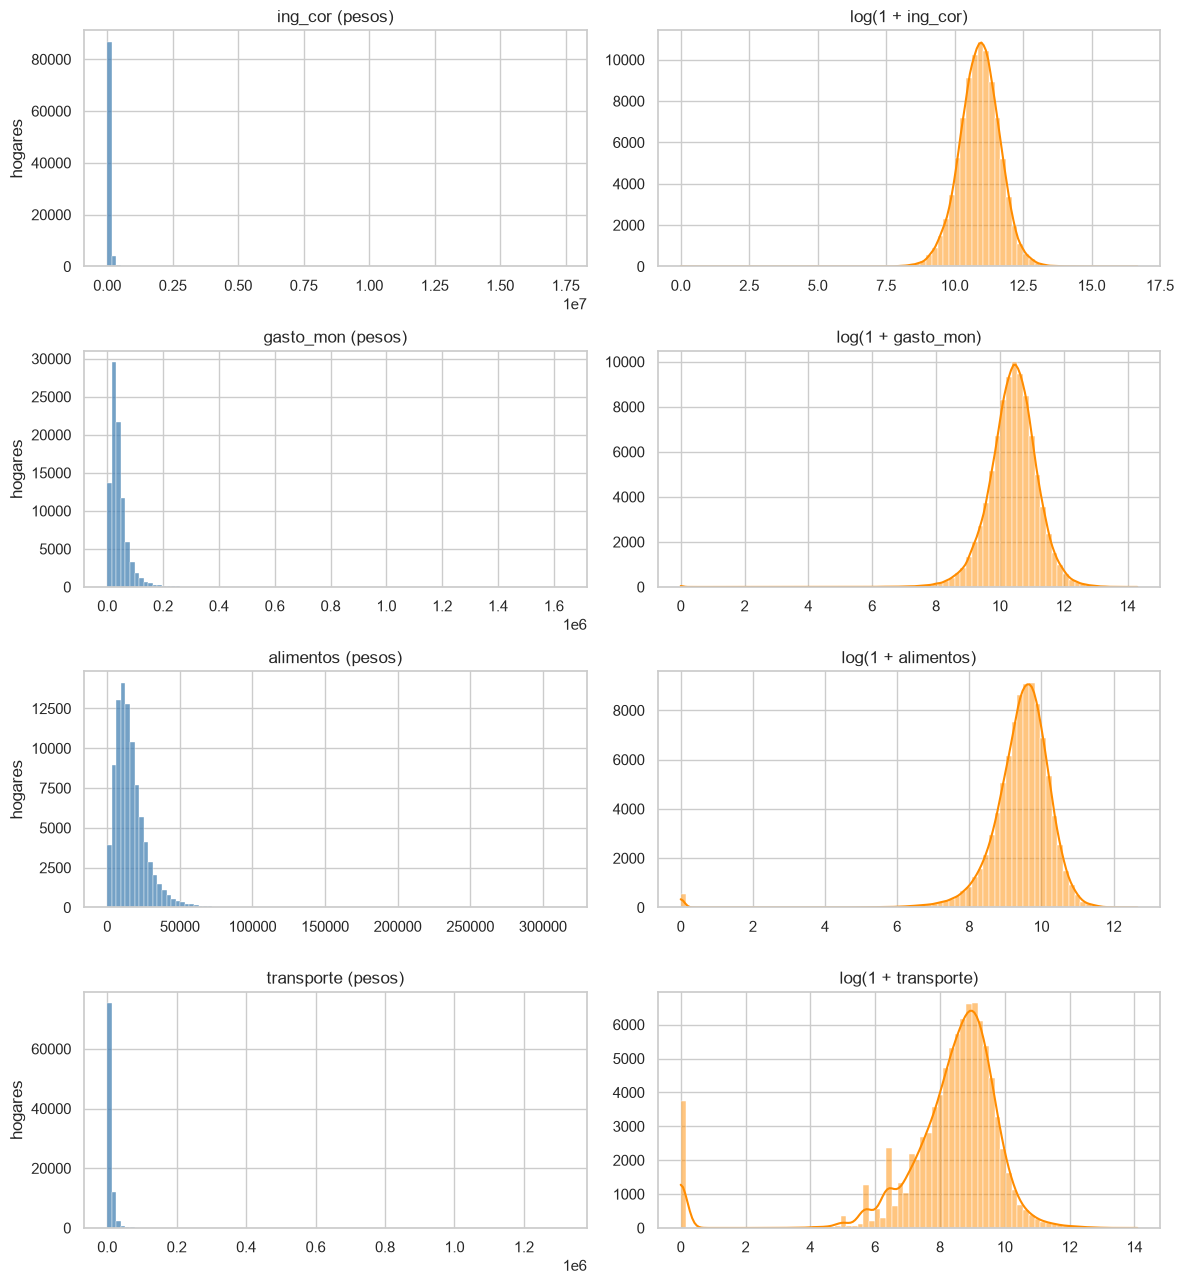

In [17]:
fig, axes = plt.subplots(4, 2, figsize=(12, 13))
for fila, col in zip(axes, ["ing_cor", "gasto_mon", "alimentos", "transporte"]):
    sns.histplot(df[col], bins=100, ax=fila[0], color="steelblue")
    fila[0].set(title=f"{col} (pesos)", xlabel="", ylabel="hogares")
    sns.histplot(np.log1p(df[col]), bins=80, kde=True, ax=fila[1], color="darkorange")
    fila[1].set(title=f"log(1 + {col})", xlabel="", ylabel="")
plt.tight_layout()
plt.show()

En pesos no se ve nada: todo se amontona a la izquierda y la cola se va hasta millones. Con log(1 + x) el ingreso y el gasto quedan con una forma de campana bastante decente (se parecen a una lognormal). En transporte y alimentos aparece una barrita sola en cero: son los hogares que no reportan nada de eso y el log no los puede acomodar en la campna.

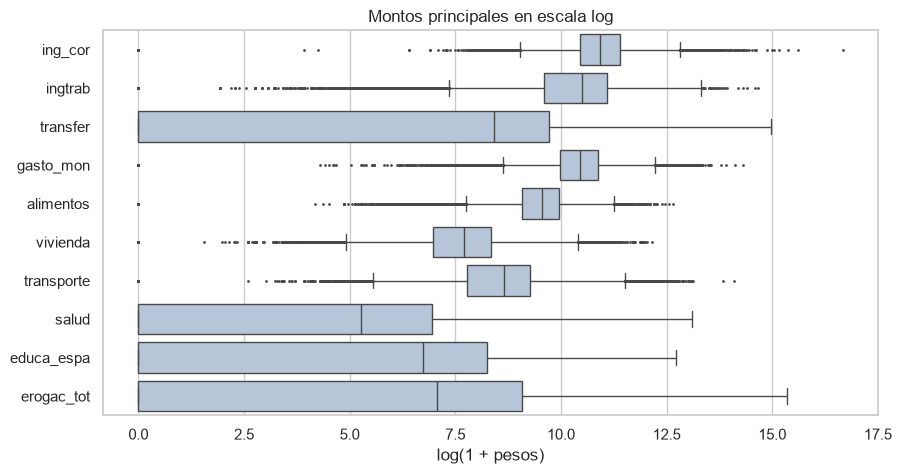

In [18]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=np.log1p(df[principales]), orient="h", ax=ax, color="lightsteelblue", fliersize=1)
ax.set(xlabel="log(1 + pesos)", title="Montos principales en escala log")
plt.show()

Variables discretas

In [19]:
df[discretas].describe().T

,count,mean,std,min,25%,50%,75%,max
edad_jefe,"91,414.00",51.54,15.99,14.00,39.00,51.00,63.00,106.00
tot_integ,"91,414.00",3.37,1.75,1.00,2.00,3.00,4.00,20.00
hombres,"91,414.00",1.63,1.10,0.00,1.00,1.00,2.00,13.00
mujeres,"91,414.00",1.75,1.16,0.00,1.00,2.00,2.00,11.00
mayores,"91,414.00",2.76,1.35,1.00,2.00,2.00,4.00,15.00
menores,"91,414.00",0.61,0.92,0.00,0.00,0.00,1.00,9.00
p12_64,"91,414.00",2.41,1.48,0.00,1.00,2.00,3.00,14.00
p65mas,"91,414.00",0.35,0.63,0.00,0.00,0.00,1.00,5.00
ocupados,"91,414.00",1.63,1.08,0.00,1.00,1.00,2.00,13.00
percep_ing,"91,414.00",2.19,1.15,0.00,1.00,2.00,3.00,14.00


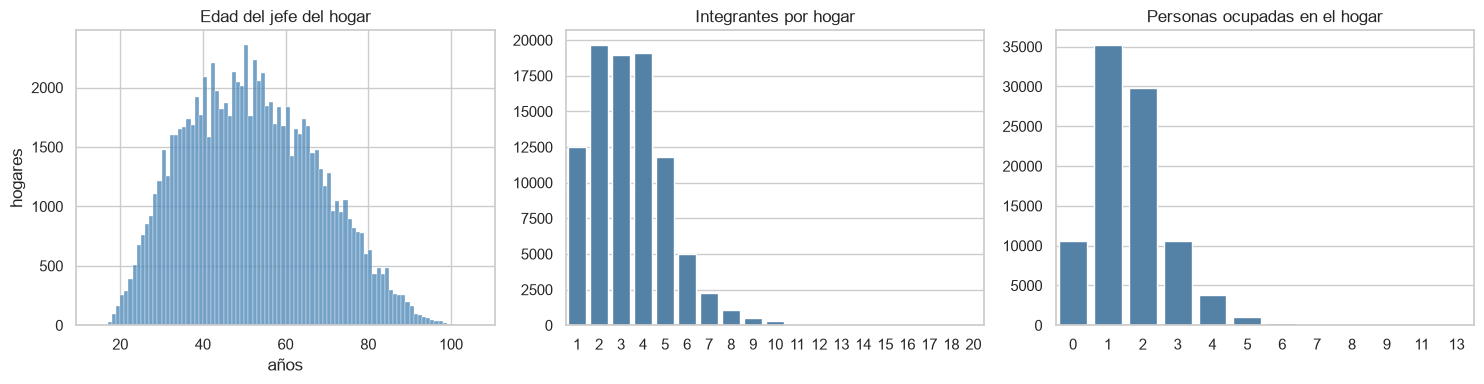

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df["edad_jefe"], binwidth=1, ax=axes[0], color="steelblue")
axes[0].set(title="Edad del jefe del hogar", xlabel="años", ylabel="hogares")
sns.countplot(x=df["tot_integ"], ax=axes[1], color="steelblue")
axes[1].set(title="Integrantes por hogar", xlabel="", ylabel="")
sns.countplot(x=df["ocupados"], ax=axes[2], color="steelblue")
axes[2].set(title="Personas ocupadas en el hogar", xlabel="", ylabel="")
plt.tight_layout()
plt.show()

El jefe del hogar tiene 51 años en mediana y el hogar típico es de 3 personas. Hay unos cuantos casos raros pero posibles: 34 jefes de hogar menores de 18 años y 228 hogares con más de 10 integrantes. No parecen errores, solo son poco comunes.

### Las categóricas

Frecuencias, la moda y la entropía. La entropía nos dice qué tan repartidos están los hogares entre categorías: si la dividimos entre el máximo posible (todas las categorías igual de grandes) queda entre 0 y 1, donde 1 es perfectamente parejo y cerca de 0 es que casi todos caen en lo mismo.

In [21]:
categoricas = ["entidad", "tam_loc", "est_socio", "clase_hog", "sexo_jefe", "educa_jefe"]

filas = []
for col in categoricas:
    frec = df[col + "_et"].value_counts()
    p = frec / frec.sum()
    filas.append({"variable": col, "categorías": len(frec), "moda": frec.idxmax(),
                  "% moda": p.max() * 100, "entropía_norm": stats.entropy(p) / np.log(len(frec))})
pd.DataFrame(filas).set_index("variable")

,categorías,moda,% moda,entropía_norm
variable,,,,
entidad,32,Chihuahua,5.21,0.99
tam_loc,4,"Menos de 2,500",39.19,0.89
est_socio,4,Medio bajo,50.74,0.87
clase_hog,5,Nuclear,61.74,0.60
sexo_jefe,2,Hombre,67.66,0.91
educa_jefe,11,Secundaria completa,27.22,0.84


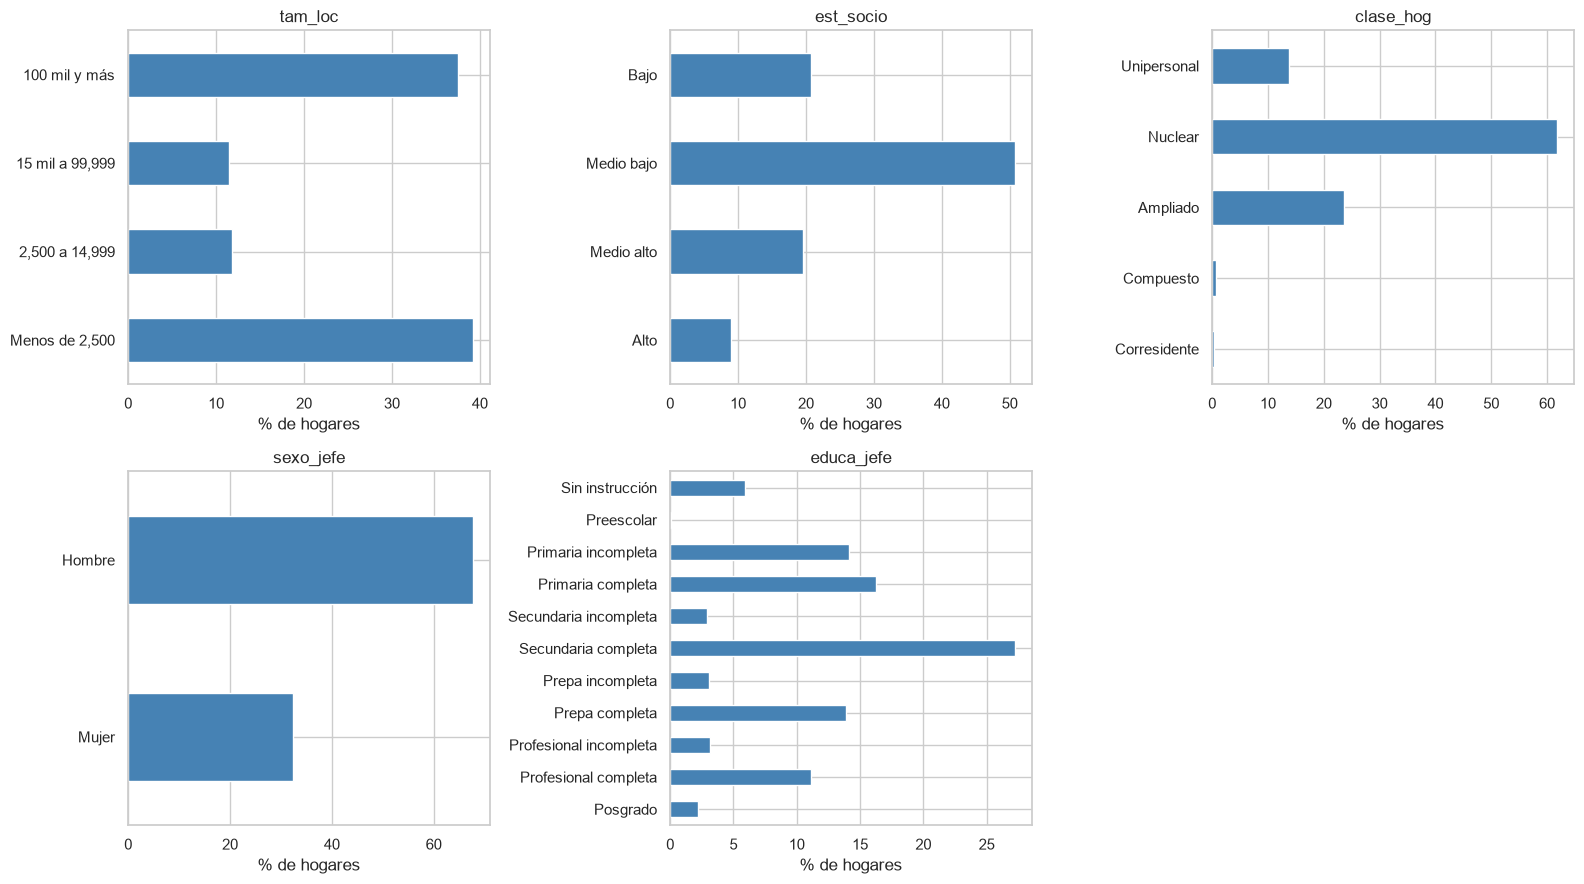

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flat, ["tam_loc", "est_socio", "clase_hog", "sexo_jefe", "educa_jefe"]):
    pct = df[col + "_et"].value_counts(normalize=True, sort=False).mul(100)
    pct.plot.barh(ax=ax, color="steelblue")
    ax.invert_yaxis()
    ax.set(title=col, xlabel="% de hogares", ylabel="")
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

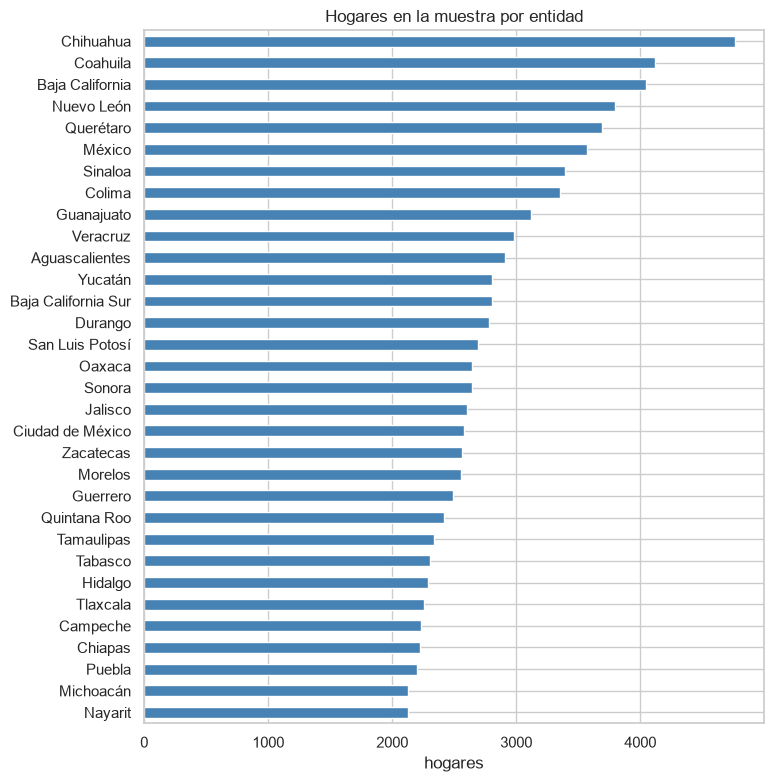

In [23]:
fig, ax = plt.subplots(figsize=(8, 9))
df["entidad_et"].value_counts().sort_values().plot.barh(ax=ax, color="steelblue")
ax.set(title="Hogares en la muestra por entidad", xlabel="hogares", ylabel="")
plt.show()

Lo que más llama la atención:

- **tam_loc**: 39% de los hogares de la muestra están en localidades de menos de 2,500 habitantes. Se me hace demasiado para México. revisar con el factor de expansión
- **est_socio**: la mitad es medio bajo y el estrato alto es el más chico
- **clase_hog**: la más desbalanceada (entropía 0.60). 62% son hogares nucleares, y compuestos y corresidentes casi no hay (565 y 323 hogares)
- **educa_jefe**: preescolar tiene solo 27 hogares. Es una categoría tan chica que podríamos juntarla con "sin instrucción" si la usamos.
- **entidad**: muy pareja (entropía 0.99), cada estado tiene entre 2 y 5 mil hogares. Eso no se parece a la población real, porque la Ciudad de México o el Estado de México tienen muchísimos más hogares que Colima. La muestra se diseñó para tener suficientes casos por estado.

### Valores extremos

Con colas tan largas, la regla de siempre (más allá de 1.5 veces el rango intercuartil) va a marcar a muchísimos hogares. Comparamos qué pasa en pesos y en log, y qué tan lejos está el máximo del percentil 99.

In [24]:
def pct_fuera_iqr(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean() * 100

atipicos = pd.DataFrame({
    "% fuera IQR (pesos)": df[principales].apply(pct_fuera_iqr),
    "% fuera IQR (log)": np.log1p(df[principales]).apply(pct_fuera_iqr),
    "p99": df[principales].quantile(0.99),
    "p99.9": df[principales].quantile(0.999),
    "max": df[principales].max(),
})
atipicos["max / p99"] = atipicos["max"] / atipicos["p99"]
atipicos

,% fuera IQR (pesos),% fuera IQR (log),p99,p99.9,max,max / p99
ing_cor,5.42,1.40,"309,771.86","688,216.51","17,431,977.54",56.27
ingtrab,4.34,14.37,"226,078.44","457,381.85","2,347,826.08",10.39
transfer,7.64,0.00,"113,671.83","237,485.65","3,200,868.40",28.16
gasto_mon,5.68,2.38,"186,293.40","396,168.83","1,635,931.14",8.78
alimentos,4.17,3.07,"57,110.33","98,825.06","314,459.88",5.51
vivienda,8.84,5.07,"25,597.81","60,963.27","190,500.00",7.44
transporte,5.84,5.30,"59,264.48","203,528.56","1,315,006.37",22.19
salud,12.35,0.00,"21,326.07","78,950.13","493,043.47",23.12
educa_espa,10.91,0.00,"40,088.02","110,055.37","336,507.11",8.39
erogac_tot,10.72,0.00,"102,338.16","328,343.78","4,677,172.12",45.70


In [25]:
# los 10 hogares con más ingreso, ¿se ven creíbles?
cols_ver = ["ing_cor", "ingtrab", "rentas", "transfer", "gasto_mon", "tot_integ", "est_socio_et", "educa_jefe_et"]
df.nlargest(10, "ing_cor")[cols_ver]

,ing_cor,ingtrab,rentas,transfer,gasto_mon,tot_integ,est_socio_et,educa_jefe_et
54315,"17,431,977.54","2,347,826.08","15,026,086.95",0.00,"203,185.17",2,Alto,Profesional completa
24677,"5,984,481.63",0.00,"5,978,481.63",0.00,"71,098.90",6,Bajo,Sin instrucción
46679,"4,753,025.72",0.00,"4,721,311.46","7,714.26","80,999.34",2,Medio alto,Profesional completa
24665,"3,845,659.85",0.00,"3,834,046.95",0.00,"55,621.27",5,Bajo,Secundaria completa
53217,"3,442,874.83","301,648.33","2,967,032.96",0.00,"1,350,676.39",3,Alto,Profesional completa
40267,"3,262,498.83",0.00,"61,630.43","3,200,868.40","122,953.68",2,Alto,Prepa completa
55199,"2,899,494.17","82,956.50","2,787,505.42",0.00,"129,730.47",4,Medio bajo,Profesional completa
2100,"2,223,683.59",0.00,"2,211,983.60","2,699.99","33,838.16",4,Medio bajo,Secundaria completa
50518,"2,197,032.78","2,188,032.78",0.00,0.00,"25,523.52",2,Bajo,Secundaria completa
54099,"2,153,980.70","138,196.70",0.00,"2,000,784.00","165,182.16",6,Medio alto,Prepa completa


En pesos, entre 4% y 12% de los hogares quedan "fuera" según la regla del IQR. Son demasiados para llamarles atipicos, es solo la cola larga de la distribución. En log el número baja mucho. La excepción es `ingtrab`: el 12% de hogares sin ingreso por trabajo (jubilados, por ejemplo) quedan lejísimos de los demás.

El ingreso corriente máximo es 56 veces el percentil 99. Al revisar los hogares más ricos se ve que casi todo su ingreso viene de `rentas`: 15 millones en un solo trimestre para un hogar de 2 personas. No parece un error de captura, más bien parece que son ingresos por negocios o propiedades que se cobran pocas veces. Algunos se ven raros (estrato bajo y sin instrucción con 6 millones en rentas), pero no tenemos con qué decir que están mal la verdad. Por ahora no borro nada. Para el futuro: Si un modelo resulta sensible a estos casos, la opción es clipping en el percentil 99 o trabajar en log.

### Escalas
Mas adelante habrá que escalar.

In [26]:
escalas = df[discretas + principales].agg(["min", "median", "max"]).T
escalas["orden_magnitud_max"] = np.floor(np.log10(escalas["max"].clip(lower=1))).astype(int)
escalas.sort_values("max")

,min,median,max,orden_magnitud_max
p65mas,0.00,0.00,5.00,0
menores,0.00,0.00,9.00,0
mujeres,0.00,2.00,11.00,1
hombres,0.00,1.00,13.00,1
perc_ocupa,0.00,1.00,13.00,1
ocupados,0.00,1.00,13.00,1
p12_64,0.00,2.00,14.00,1
percep_ing,0.00,2.00,14.00,1
mayores,1.00,2.00,15.00,1
tot_integ,1.00,3.00,20.00,1


### Relaciones entre variables

Spearman en vez de Pearson porque los montos están muy sesgados y con muchos ceros; Spearman trabaja con rangos y no se deja jalar por los extremos.

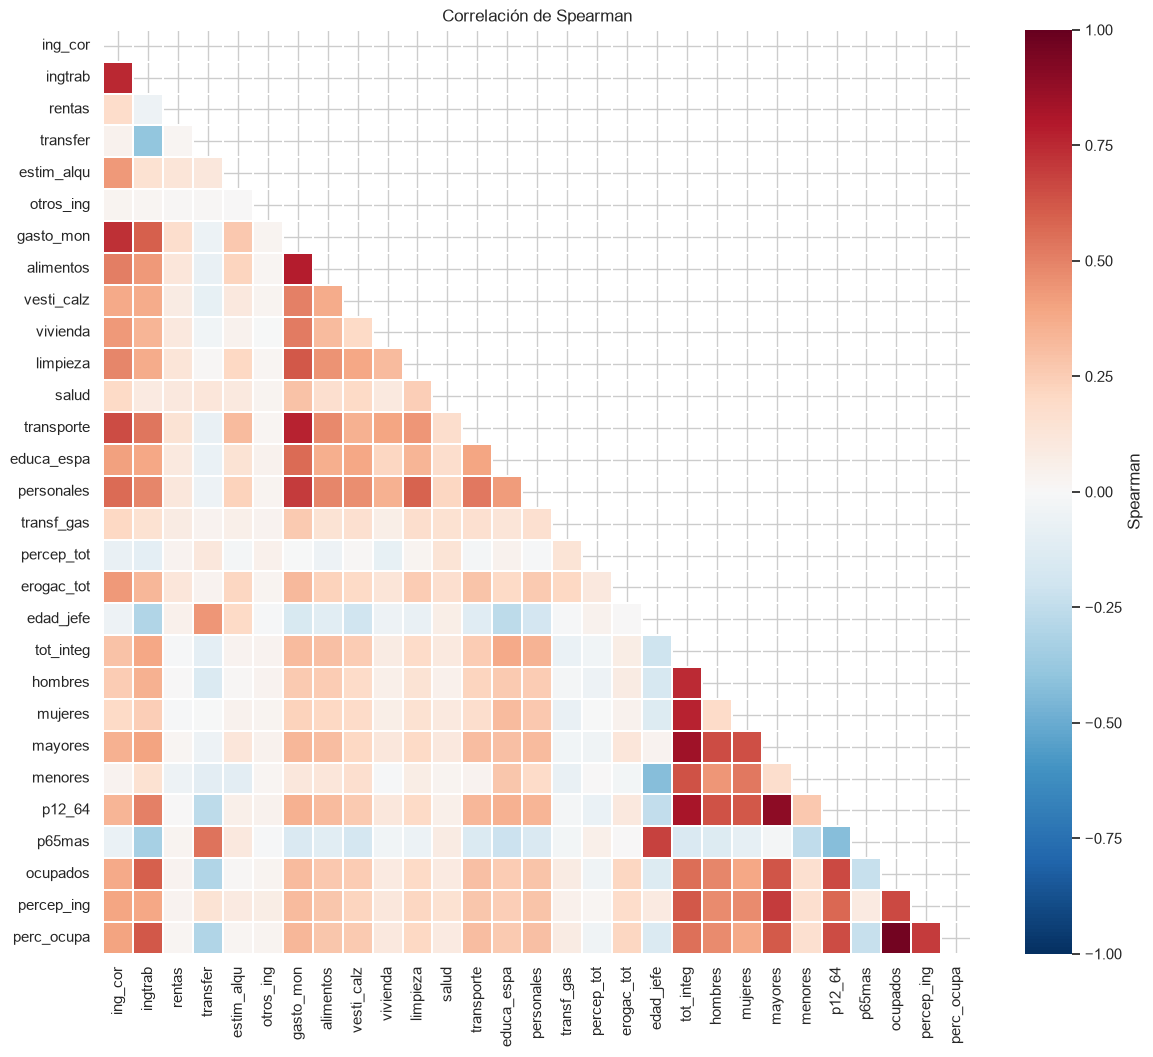

In [27]:
totales = ["ing_cor", "ingtrab", "rentas", "transfer", "estim_alqu", "otros_ing",
           "gasto_mon", "alimentos", "vesti_calz", "vivienda", "limpieza", "salud", "transporte",
           "educa_espa", "personales", "transf_gas", "percep_tot", "erogac_tot"]
corr = df[totales + discretas].corr(method="spearman")

mascara = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(corr, mask=mascara, cmap="RdBu_r", vmin=-1, vmax=1, center=0, ax=ax,
            cbar_kws={"label": "Spearman"}, linewidths=0.3)
ax.set_title("Correlación de Spearman")
plt.show()

In [28]:
# Pearson vs Spearman en un par: los extremos cambian bastante la historia
for a, b in [("ing_cor", "gasto_mon"), ("ing_cor", "salud"), ("tot_integ", "alimentos")]:
    print(f"{a} vs {b}:  Pearson {stats.pearsonr(df[a], df[b])[0]:.2f}"
          f"  Spearman {stats.spearmanr(df[a], df[b])[0]:.2f}")

ing_cor vs gasto_mon:  Pearson 0.48  Spearman 0.73
ing_cor vs salud:  Pearson 0.16  Spearman 0.20
tot_integ vs alimentos:  Pearson 0.24  Spearman 0.30


Con 91 mil hogares cualquier correlación, por chiquita que sea, sale con p-value prácticamente cero, así que aquí el p-value no nos ayuda a decidir; vale más fijarse en el tamaño. Buscar los pares redundantes en toda la base (todos los montos y discretas), los que tienen |ρ| > 0.9:

In [29]:
corr_todo = df[montos + discretas].corr(method="spearman")
pares = (corr_todo.where(np.triu(np.ones_like(corr_todo, dtype=bool), k=1))
         .stack().rename("spearman").reset_index())
pares = pares[pares["spearman"].abs() > 0.9].sort_values("spearman", ascending=False)

# marcamos si el par es total-componente según la jerarquía de arriba
def es_padre_hijo(a, b):
    return b in jerarquia.get(a, []) or a in jerarquia.get(b, [])
pares["total_y_parte"] = [es_padre_hijo(a, b) for a, b in zip(pares["level_0"], pares["level_1"])]
pares

,level_0,level_1,spearman,total_y_parte
8397,mantenim,combus,0.99,True
231,trabajo,sueldos,0.98,True
12767,ocupados,perc_ocupa,0.97,False
9316,personales,cuida_pers,0.91,True


con Spearman solo salen 4 pares arriba de 0.9 aunque la base está llena de totales y partes. Me imagino que pasa porque las partes casi siempre valen cero y el total no asi que en rangos no se parecen tanto. Los que sí son casi lo mismo:

- `mantenim` y `combus`: casi todo el mantenimiento de vehículos es gasolina.
- `trabajo` y `sueldos`: casi todo el ingreso por trabajo es sueldo.
- `ocupados` y `perc_ocupa`: personas ocupadas y personas ocupadas con ingreso. Prácticamente cuentan lo mismo.
- `personales` y `cuida_pers`

Pues en cada par basta con quedarnos con una.

También se ve la diferencia entre Pearson y Spearman: para ingreso contra gasto, Pearson da 0.48 y Spearman 0.73. Los hogares con ingresos gigantes y gasto normal le bajan mucho a Pearson.

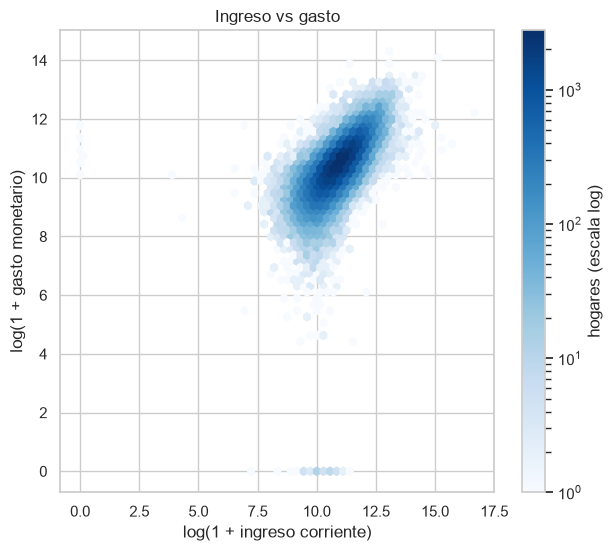

In [30]:
fig, ax = plt.subplots(figsize=(7, 6))
hb = ax.hexbin(np.log1p(df["ing_cor"]), np.log1p(df["gasto_mon"]), gridsize=60, cmap="Blues", mincnt=1, bins="log")
fig.colorbar(hb, label="hogares (escala log)")
ax.set(xlabel="log(1 + ingreso corriente)", ylabel="log(1 + gasto monetario)", title="Ingreso vs gasto")
plt.show()

Ahora números contra categorías. Vemos el ingreso (en log) por estrato, tamaño de localidad y educación del jefe.

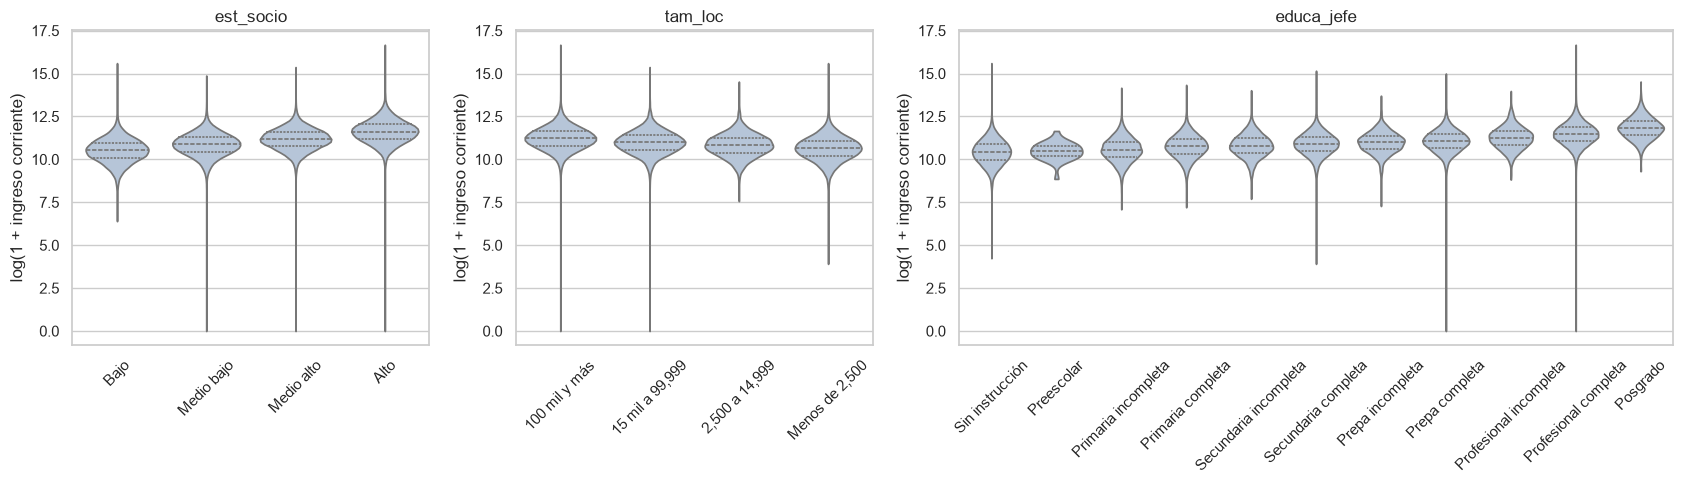

In [31]:
df["log_ing_cor"] = np.log1p(df["ing_cor"])

fig, axes = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw={"width_ratios": [1, 1, 2]})
for ax, col in zip(axes, ["est_socio", "tam_loc", "educa_jefe"]):
    sns.violinplot(data=df, x=col + "_et", y="log_ing_cor", ax=ax, color="lightsteelblue", inner="quartile", cut=0)
    ax.set(xlabel="", ylabel="log(1 + ingreso corriente)", title=col)
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

Para ponerle número a lo que se ve usamos ANOVA de una vía: compara las medias de cada grupo. Además del p-value calculamos η² (qué parte de la varianza del ingreso explican los grupos), que es lo que de verdad nos dice si la diferencia es grande.

In [32]:
def anova(num, cat):
    grupos = [g[num].values for _, g in df.groupby(cat, observed=True)]
    f, p = stats.f_oneway(*grupos)
    media = df[num].mean()
    ss_entre = sum(len(g) * (g.mean() - media) ** 2 for g in grupos)
    ss_total = ((df[num] - media) ** 2).sum()
    return pd.Series({"F": f, "p_value": p, "eta2": ss_entre / ss_total})

pd.DataFrame({c: anova("log_ing_cor", c) for c in categoricas}).T.sort_values("eta2", ascending=False)

,F,p_value,eta2
educa_jefe,"1,949.55",0.00,0.18
est_socio,"6,208.88",0.00,0.17
tam_loc,"4,363.39",0.00,0.13
entidad,276.95,0.00,0.09
clase_hog,"1,811.57",0.00,0.07
sexo_jefe,409.66,0.00,0.00


Todas dan p-value de cero, otra vez por el tamaño de la muestra. Lo que sí sirve es η²: la educación del jefe (0.18) y el estrato (0.17) son las que más separan el ingreso, seguidas del tamaño de localidad (0.13). En los violines se ve clarito: la mediana del ingreso pasa de unos 34 mil sin instrucción a 135 mil con posgrado.

El sexo del jefe en cambio casi no separa nada (η² ≈ 0). Los hogares con jefa ganan un poco menos en mediana, pero las distribuciones se enciman casi por completo.

Y categorías contra categorías. Primero una tabla de contingencia (en % por fila) entre tamaño de localidad y estrato:

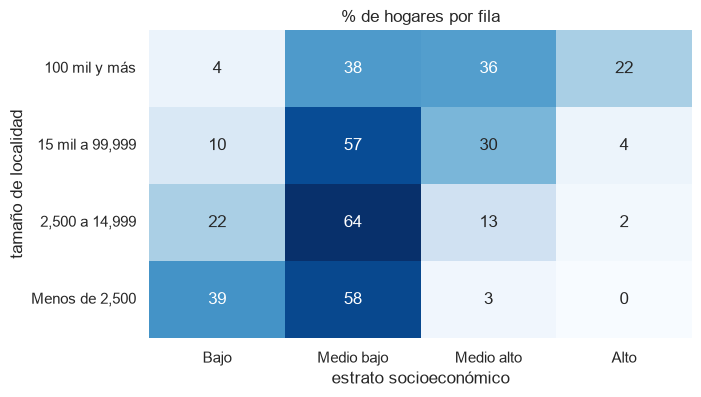

In [33]:
tabla = pd.crosstab(df["tam_loc_et"], df["est_socio_et"], normalize="index").mul(100)
fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(tabla, annot=True, fmt=".0f", cmap="Blues", ax=ax, cbar=False)
ax.set(xlabel="estrato socioeconómico", ylabel="tamaño de localidad", title="% de hogares por fila")
plt.show()

Para todas las parejas de categóricas a la vez usamos información mutua normalizada (0 = no se dicen nada, 1 = una determina a la otra).

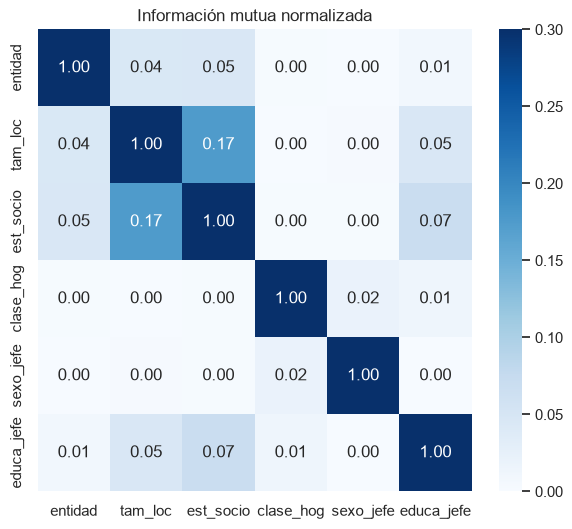

In [34]:
im = pd.DataFrame(index=categoricas, columns=categoricas, dtype=float)
for a in categoricas:
    for b in categoricas:
        im.loc[a, b] = normalized_mutual_info_score(df[a].astype(str), df[b].astype(str))

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(im, annot=True, fmt=".2f", cmap="Blues", ax=ax, vmin=0, vmax=0.3)
ax.set_title("Información mutua normalizada")
plt.show()

La verdad las categóricas casi no se repiten entre ellas. La pareja que más comparte es tamaño de localidad con estrato (0.17), y tiene sentido: en localidades de menos de 2,500 habitantes casi no hay estrato alto (0%), mientras que en las ciudades grandes 22% lo son. Las demás parejas andan cerca de cero, así que cada una aporta algo distinto.

### El factor de expansión

Cada hogar de la muestra representa a muchos hogares del país, y no a la misma cantidad. Todo lo de arriba describe a la muestra; si quisiéramos hablar de México habría que ponderar con `factor`. Veamos qué tanto cambia.

In [35]:
print(f"hogares en la muestra: {len(df):,}")
print(f"hogares que representan: {df['factor'].sum():,.0f}")
df["factor"].describe()

hogares en la muestra: 91,414
hogares que representan: 38,830,230


count   91,414.00
mean       424.77
std        474.68
min          4.00
25%        141.00
50%        288.00
75%        526.00
max      7,127.00
Name: factor, dtype: float64

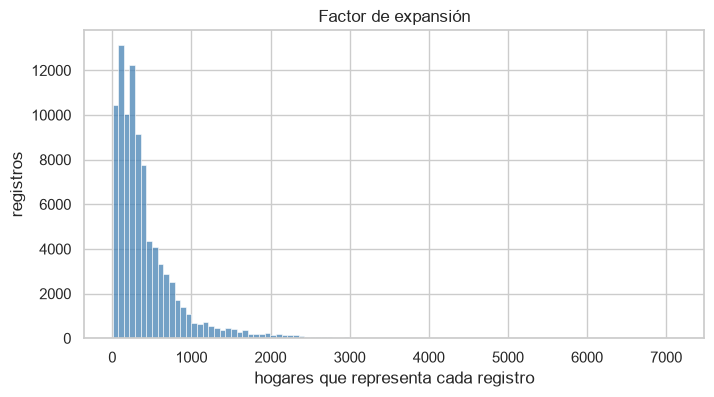

In [36]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(df["factor"], bins=100, ax=ax, color="steelblue")
ax.set(title="Factor de expansión", xlabel="hogares que representa cada registro", ylabel="registros")
plt.show()

In [37]:
w = df["factor"]
comparacion = pd.DataFrame({
    "muestra": [df["ing_cor"].mean(), df["gasto_mon"].mean(), (df["sexo_jefe"] == 2).mean() * 100,
                (df["tam_loc"] == 4).mean() * 100, (df["est_socio"] == 1).mean() * 100],
    "ponderado": [np.average(df["ing_cor"], weights=w), np.average(df["gasto_mon"], weights=w),
                  np.average(df["sexo_jefe"] == 2, weights=w) * 100,
                  np.average(df["tam_loc"] == 4, weights=w) * 100,
                  np.average(df["est_socio"] == 1, weights=w) * 100],
}, index=["ingreso corriente medio", "gasto monetario medio", "% jefa mujer",
          "% localidades < 2,500 hab.", "% estrato bajo"])
comparacion["diferencia_%"] = (comparacion["ponderado"] / comparacion["muestra"] - 1) * 100
comparacion

,muestra,ponderado,diferencia_%
ingreso corriente medio,"72,273.59","77,863.84",7.73
gasto monetario medio,"43,411.37","47,674.37",9.82
% jefa mujer,32.34,33.54,3.72
"% localidades < 2,500 hab.",39.19,20.47,-47.77
% estrato bajo,20.71,15.58,-24.79


Los 91 mil hogares representan a 38.8 millones de hogares, y el factor va de 4 a más de 7 mil. Ponderar cambia bastante las cosas: en la muestra 39% de los hogares son de localidades de menos de 2,500 habitantes, pero en el país son 20%. El estrato bajo también está sobrerrepresentado (21% contra 16%). Como que la encuesta muestrea de mas a los hogares rurales y pobres para tener suficientes casos.

si queremos decir algo de "los hogares de México" hay que usar el factor. Si solo describimos la muestra o entrenamos un modelo, hay que tener presente que la muestra no se parece al país.

### Observaciones

- No hay nulos, pero sí muchísimos ceros: 68 de 103 montos son cero en más de la mitad de los hogares. Muchos de esos ceros quieren decir "no gastó" y no "no sabemos".
- `smg` es constante, se puede tirar
- La base es un árbol de sumas que cuadra perfecto (ingreso, gasto, erogaciones, personas). No hay que meter un total con todas sus partes. `refaccion` y `combus` cuelgan de `mantenim`, no directo de `transporte`.
- Pares casi idénticos: `ocupados`/`perc_ocupa`, `trabajo`/`sueldos`, `mantenim`/`combus`, `personales`/`cuida_pers`.
- Los montos tienen colas larguísimas. En log se ven razonables. En pesos, la media y la desviación estándar engañan.
- Hay hogares con ingresos de millones, casi todos por rentas. No los borramos, pero hay que decidir qué hacer con ellos (log, recortar en p99 o dejarlos).
- Las escalas van de unidades (personas) a millones (pesos), asi que habrá que escalar
- Entre las categóricas, educación del jefe, estrato y tamaño de localidad son las que más se relacionan con el ingreso. El sexo del jefe casi no.
- Categorías muy chicas: preescolar en `educa_jefe`, compuesto y corresidente en `clase_hog`.
- La muestra no se parece al país: está cargada a lo rural y al estrato bajo. Para hablar de México hay que ponderar con `factor`.

Ver los montos a nivel de las ramas del árbol (no solo los totales), revisar si hay patrones por entidad y decidir cómo tratar los ceros.